# Inventory Demand Forecast — 5 SKUs, 36 Months

Goal: forecast the next 6 months of demand for a small product catalog. I'm using a synthetic series with trend + yearly seasonality + noise per SKU. Each SKU has its own level and seasonality shape (e.g. SKU-3 is summer-heavy).

Per-SKU SARIMA. I considered Prophet but it's overkill for 36 monthly observations and adds a dependency I don't need.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

rng = np.random.default_rng(3)
OUT = Path('../../data/inventory'); OUT.mkdir(parents=True, exist_ok=True)

In [2]:
MONTHS = 36
dates = pd.date_range('2022-01-01', periods=MONTHS, freq='MS')
SKUS = {
    'SKU-1': dict(level=200, trend=2.0, season_amp=30, season_peak=12),  # winter peak
    'SKU-2': dict(level=120, trend=0.5, season_amp=10, season_peak=6),
    'SKU-3': dict(level=400, trend=-1.5, season_amp=80, season_peak=7),  # summer peak
    'SKU-4': dict(level=80,  trend=3.0, season_amp=5,  season_peak=11),
    'SKU-5': dict(level=300, trend=0.0, season_amp=40, season_peak=3),
}
rows = []
for sku, p in SKUS.items():
    t = np.arange(MONTHS)
    season = p['season_amp'] * np.cos(2 * np.pi * (t + 1 - p['season_peak']) / 12)
    noise = rng.normal(0, p['level'] * 0.05, MONTHS)
    y = p['level'] + p['trend'] * t + season + noise
    y = np.clip(y, 0, None).round()
    for d, v in zip(dates, y):
        rows.append({'date': d, 'sku': sku, 'demand': v})
df = pd.DataFrame(rows)
df.to_csv(OUT / 'demand.csv', index=False)
print(df.shape); df.head(6)

(180, 3)


,date,sku,demand
0,2022-01-01,SKU-1,246.0
1,2022-02-01,SKU-1,191.0
2,2022-03-01,SKU-1,208.0
3,2022-04-01,SKU-1,185.0
4,2022-05-01,SKU-1,177.0
5,2022-06-01,SKU-1,178.0


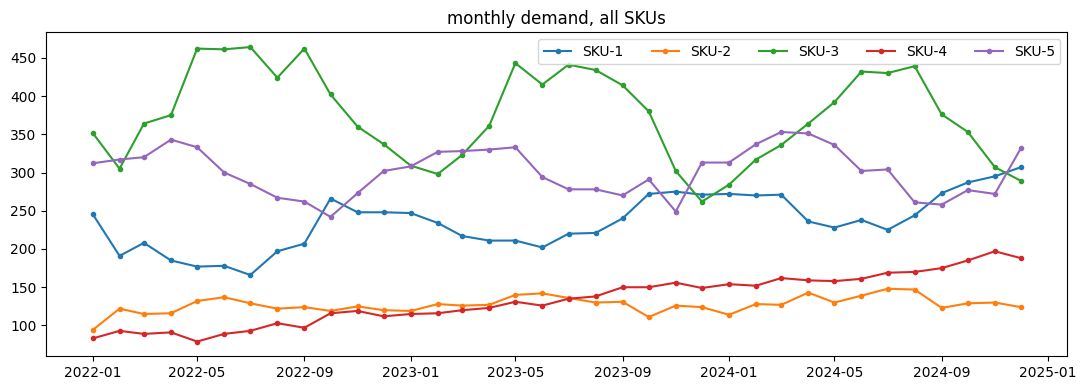

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
for sku, g in df.groupby('sku'):
    ax.plot(g['date'], g['demand'], marker='o', markersize=3, label=sku)
ax.set_title('monthly demand, all SKUs'); ax.legend(ncol=5)
plt.tight_layout(); plt.show()

## Fit one SARIMA per SKU

Order is (1, 1, 1)(1, 1, 0, 12). With 36 points and a 12-month seasonal cycle there isn't much room to fit a richer spec — only 3 full seasonal periods. Forecasting 6 months out is therefore roughly at the limit of what this data supports.

In [4]:
FORECAST_H = 6
forecasts = {}
for sku, g in df.groupby('sku'):
    s = g.set_index('date')['demand'].asfreq('MS')
    model = SARIMAX(s, order=(1,1,1), seasonal_order=(1,1,0,12))
    res = model.fit(disp=False)
    fc = res.get_forecast(steps=FORECAST_H)
    forecasts[sku] = {
        'history': s,
        'mean':    fc.predicted_mean,
        'ci':      fc.conf_int(alpha=0.2),  # 80% interval is enough for inventory planning
    }
    print(f'{sku}  AIC={res.aic:.1f}')

SKU-1  AIC=194.5


SKU-2  AIC=174.1


SKU-3  AIC=227.4


SKU-4  AIC=152.2


SKU-5  AIC=200.7


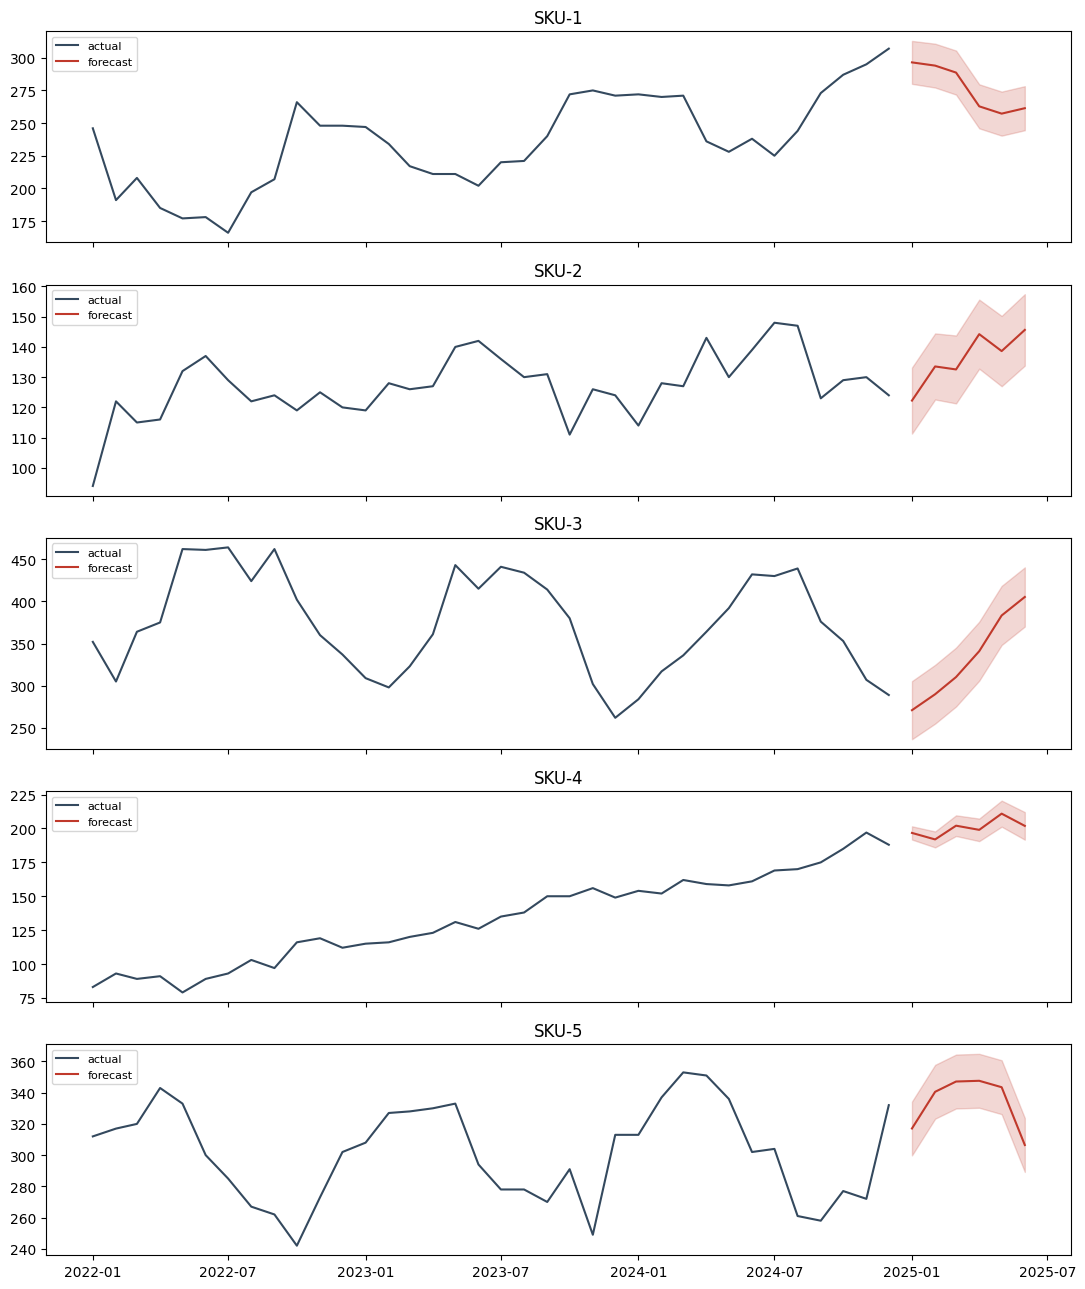

In [5]:
fig, axes = plt.subplots(len(forecasts), 1, figsize=(11, 2.6 * len(forecasts)), sharex=True)
for ax, (sku, f) in zip(axes, forecasts.items()):
    h = f['history']; m = f['mean']; ci = f['ci']
    ax.plot(h.index, h.values, label='actual', color='#34495e')
    ax.plot(m.index, m.values, label='forecast', color='#c0392b')
    ax.fill_between(m.index, ci.iloc[:, 0], ci.iloc[:, 1], color='#c0392b', alpha=0.2)
    ax.set_title(sku); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
# Roll the forecasts into a planning table.
out = []
for sku, f in forecasts.items():
    for d, v in zip(f['mean'].index, f['mean'].values):
        out.append({'sku': sku, 'month': d.strftime('%Y-%m'), 'forecast': round(float(v))})
plan = pd.DataFrame(out)
plan.pivot(index='month', columns='sku', values='forecast')

sku,SKU-1,SKU-2,SKU-3,SKU-4,SKU-5
month,,,,,
2025-01,296,122,271,197,317
2025-02,294,134,290,192,341
2025-03,289,133,310,202,347
2025-04,263,144,341,199,348
2025-05,257,139,383,211,344
2025-06,261,146,405,202,306


## Notes

- I generated the data, so seeing SARIMA recover the seasonality isn't a model endorsement — it's a unit test. On real demand data I'd expect promotions, stockouts, and price changes to dominate and mess everything up.
- The 80% CIs are wide on the SKUs with low signal. That width is honest; what managers usually want from a forecast is *bounds* for ordering decisions, not a point estimate.
- A hierarchical approach (forecast at the category level, then disaggregate) usually beats per-SKU on real catalogs. With 5 SKUs the hierarchy is too small to bother.